Chatbot Reading Existing Memories

In [1]:
from dotenv import load_dotenv
load_dotenv()

from langchain_groq import ChatGroq
from langchain_core.runnables import RunnableConfig
from langchain_core.messages import SystemMessage

from langgraph.graph import StateGraph,START,END,MessagesState
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore

In [2]:
# 1) create ltm store + seed memories (done before running the graph)
store=InMemoryStore()

user_id="u1"

#store user detail as a single blob 
user_details=("user",user_id,"details")

store.put(user_details,"profile_1",{"data":"Name:Nitish"})
store.put(user_details,"profile_2",{"data":"Profession:Teaches AI on youtube"})
store.put(user_details,"preference_1",{"data":"prefer concies answer"})
store.put(user_details,"preference_2",{"data":"Likes examples in python"})
store.put(user_details,"project_1",{"data":"building MCP server (python based project)"})

In [3]:
# 2)system prompt template (your prompt)
SYSTEM_PROMPT_TEMPLATE = """You are a helpful assistant with memory capabilities.
If user-specific memory is available, use it to personalize 
your responses based on what you know about the user.

Your goal is to provide relevant, friendly, and tailored 
assistance that reflects the user’s preferences, context, and past interactions.

If the user’s name or relevant personal context is available, always personalize your responses by:
    – Always Address the user by name (e.g., "Sure, Nitish...") when appropriate
    – Referencing known projects, tools, or preferences (e.g., "your MCP  server python based project")
    – Adjusting the tone to feel friendly, natural, and directly aimed at the user

Avoid generic phrasing when personalization is possible. For example, instead of "In TypeScript apps..." 
say "Since your project is built with TypeScript..."

Use personalization especially in:
    – Greetings and transitions
    – Help or guidance tailored to tools and frameworks the user uses
    – Follow-up messages that continue from past context

Always ensure that personalization is based only on known user details and not assumed.

In the end suggest 3 relevant further questions based on the current response and user profile

The user’s memory (which may be empty) is provided as: {user_details_content}
"""

In [4]:
llm=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [5]:
def chat_node(state: MessagesState, config: RunnableConfig, store: BaseStore):
    
    user_id = config["configurable"]["user_id"]

    # Read-only: fetch user details memory (no writes)
    user_details = ("user", user_id, "details")
    items = store.search(user_details)

    # Convert memory items into a string blob for {user_details_content}
    # Keep it dead simple for teaching.
    if items:
        user_details_content = "\n".join(f"- {it.value.get('data', '')}" for it in items)
    else:
        user_details_content = ""  # prompt says it may be empty

    system_prompt = SYSTEM_PROMPT_TEMPLATE.format(
        user_details_content=user_details_content
    )

    system_msg = SystemMessage(content=system_prompt)

    response = llm.invoke([system_msg] + state["messages"])
    return {"messages": [response]}

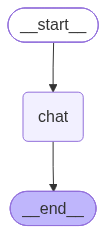

In [6]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat_node)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)

graph = builder.compile(store=store)

graph

In [7]:
# 4) Run it (provide user_id in config)
config = {"configurable": {"user_id": "u1"}}

result = graph.invoke(
    {"messages": [{"role": "user", "content": "Explain gen ai in simple terms."}]},
    config,
)

print(result["messages"][-1].content)

Sure, Nitish!  
Generative AI (Gen‑AI) is a type of artificial intelligence that **creates new content**—text, images, code, music, etc.—instead of just recognizing or classifying existing data. Think of it as a very advanced “copy‑and‑paste” tool that learns patterns from a huge dataset and then produces something that *looks* like it could have come from that same source.

### Quick Python illustration
```python
from transformers import pipeline

# Load a pre‑trained text‑generation model
generator = pipeline("text-generation", model="gpt2")

prompt = "Explain generative AI in simple terms:"
output = generator(prompt, max_length=50, num_return_sequences=1)[0]["generated_text"]

print(output)
```
Running this prints a short, human‑like explanation—exactly what Gen‑AI does.

### Why it matters for your MCP server
- **Dynamic content**: Generate user‑specific responses or documentation on the fly.
- **Automation**: Auto‑create code snippets or configuration files for your server.
- **Pe

Chatbot Creating New Memories

In [1]:
from dotenv import load_dotenv
load_dotenv()

import uuid
from typing import List
from pydantic import BaseModel,Field

from langchain_groq import ChatGroq
from langchain_core.runnables import RunnableConfig
from langchain_core.messages import SystemMessage

from langgraph.graph import StateGraph,START,END,MessagesState
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore

In [2]:
store=InMemoryStore()

In [3]:
extractor_llm=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [5]:
class MemoryDecision(BaseModel):
    should_write:bool=Field(description="whether to store any memories")
    memories:List[str]=Field(default_factory=list,description="Atomic user memories")

In [6]:
memory_extractor=extractor_llm.with_structured_output(MemoryDecision)

In [9]:
def remember_only_node(state:MessagesState,config:RunnableConfig,store:BaseStore):
    user_id=config["configurable"]["user_id"]
    namespace=("user",user_id,"details")

    #take last user message
    last_msg=state["messages"][-1].content

    # LLM decides what to store
    decision: MemoryDecision = memory_extractor.invoke(
        [
            SystemMessage(
                content=(
                    "Extract LONG-TERM memories from the user's message.\n"
                    "Only store stable, user-specific info (identity, preferences, ongoing projects).\n"
                    "Do NOT store transient info.\n"
                    "Return should_write=false if nothing is worth storing.\n"
                    "Each memory should be a short atomic sentence."
                )
            ),
            {"role": "user", "content": last_msg},
        ]
    )

    # Write to store (LTM)
    if decision.should_write:
        for mem in decision.memories:
            store.put(namespace, str(uuid.uuid4()), {"data": mem})

    # IMPORTANT: we are NOT using memory, not even responding with the LLM.
    # We just return a fixed acknowledgement.
    return {"messages": [{"role": "assistant", "content": "Noted."}]}

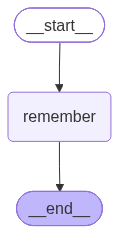

In [10]:
builder = StateGraph(MessagesState)
builder.add_node("remember", remember_only_node)
builder.add_edge(START, "remember")
builder.add_edge("remember", END)

graph = builder.compile(store=store)

graph

In [15]:
config = {"configurable": {"user_id": "u1"}}

res = graph.invoke({"messages": [{"role": "user", "content": "Hi my name is nitish"}]},config)
print("Assistant:", res["messages"][-1].content)

Assistant: Noted.


In [16]:
res = graph.invoke({"messages": [{"role": "user", "content": "I teach AI on youtube"}]},config)
print("Assistant:", res["messages"][-1].content)

Assistant: Noted.


In [17]:
res = graph.invoke({"messages": [{"role": "user", "content": "My favorite programming language is Python"}]},config)
print("Assistant:", res["messages"][-1].content)

Assistant: Noted.


In [18]:
items = store.search(("user", "u1", "details"))

for item in items:
    print(item.value['data'])

User's name is Nitish
User teaches AI on YouTube
User's favorite programming language is Python.
User's name is Nitish
User teaches AI on YouTube
User's favorite programming language is Python.


Chatbot Creating New Memories(without Duplication)

In [2]:
from dotenv import load_dotenv
load_dotenv()

import uuid
from typing import List
from pydantic import BaseModel,Field

from langchain_groq import ChatGroq
from langchain_core.runnables import RunnableConfig
from langchain_core.messages import SystemMessage

from langgraph.graph import StateGraph,START,END,MessagesState
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore

In [3]:
store=InMemoryStore()

In [4]:
memory_llm=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [5]:
class MemoryItem(BaseModel):
    text: str=Field(description="Atomic user memory as a short sentence")
    is_new: bool=Field(description="true if this memory is new and should be stored.false if duplicate/already known.")

In [6]:
class MemoryDecision(BaseModel):
    should_write:bool=Field(description="whether to store any memories")
    memories:List[MemoryItem]=Field(default_factory=list,description="Atomic user memories")

In [9]:
memory_extractor=memory_llm.with_structured_output(MemoryDecision)

In [10]:
MEMORY_PROMPT = """You are responsible for updating and maintaining accurate user memory.

CURRENT USER DETAILS (existing memories):
{user_details_content}

TASK:
- Review the user's latest message.
- Extract user-specific info worth storing long-term (identity, stable preferences, ongoing projects/goals).
- For each extracted item, set is_new=true ONLY if it adds NEW information compared to CURRENT USER DETAILS.
- If it is basically the same meaning as something already present, set is_new=false.
- Keep each memory as a short atomic sentence.
- No speculation; only facts stated by the user.
- If there is nothing memory-worthy, return an empty list.
"""

In [11]:
def chat_creates_memory_node(state: MessagesState, config: RunnableConfig, store: BaseStore):

    user_id = config["configurable"]["user_id"]

    namespace = ("user", user_id, "details")

    # A) Load existing memories
    existing_items = store.search(namespace)
    existing_texts = [it.value.get("data", "") for it in existing_items if it.value.get("data")]
    user_details_content = "\n".join(f"- {t}" for t in existing_texts) if existing_texts else "(empty)"

    # B) Latest user message
    last_text = state["messages"][-1]

    # C) LLM extracts memories + marks new vs duplicate
    decision: MemoryDecision = memory_extractor.invoke(
        [
            SystemMessage(content=MEMORY_PROMPT.format(user_details_content=user_details_content)),
            {"role": "user", "content": f"USER MESSAGE:\n{last_text}"},
        ]
    )

    # D) Store ONLY new memories
    if decision.should_write:
        for mem in decision.memories:
            if mem.is_new:
                store.put(namespace, str(uuid.uuid4()), {"data": mem.text})

    return {"messages": [{"role": "assistant", "content": "Noted."}]}

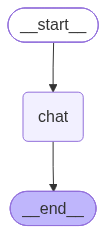

In [12]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat_creates_memory_node)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)

graph = builder.compile(store=store)

graph

In [13]:
config = {"configurable": {"user_id": "u1"}}

In [15]:
r1 = graph.invoke({"messages": [{"role": "user", "content": "My name is Nitish"}]}, config)
print("Assistant:", r1["messages"][-1].content)

Assistant: Noted.


In [16]:
# Likely duplicate of the first memory -> is_new should be false -> saved=0
r2 = graph.invoke({"messages": [{"role": "user", "content": "I like Python for programming."}]}, config)
print("\nAssistant:", r2["messages"][-1].content)


Assistant: Noted.


In [17]:
for it in store.search(("user", "u1", "details")):
    print(it.value['data'])

User's name is Nitish.
User likes Python for programming.


Merged Workflow

In [38]:
from dotenv import load_dotenv
load_dotenv()

import uuid
from typing import List
from pydantic import BaseModel, Field

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage
from langchain_core.runnables import RunnableConfig

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore

In [39]:
store = InMemoryStore()

In [40]:
SYSTEM_PROMPT_TEMPLATE = """You are a helpful assistant with memory capabilities.
If user-specific memory is available, use it to personalize 
your responses based on what you know about the user.

Your goal is to provide relevant, friendly, and tailored 
assistance that reflects the user’s preferences, context, and past interactions.

If the user’s name or relevant personal context is available, always personalize your responses by:
    – Always Address the user by name (e.g., "Sure, Nitish...") when appropriate
    – Referencing known projects, tools, or preferences (e.g., "your MCP server python based project")
    – Adjusting the tone to feel friendly, natural, and directly aimed at the user

Avoid generic phrasing when personalization is possible.

Use personalization especially in:
    – Greetings and transitions
    – Help or guidance tailored to tools and frameworks the user uses
    – Follow-up messages that continue from past context

Always ensure that personalization is based only on known user details and not assumed.

In the end suggest 3 relevant further questions based on the current response and user profile

The user’s memory (which may be empty) is provided as: {user_details_content}
"""

In [41]:
memory_llm=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [43]:
class MemoryItem(BaseModel):
    text: str = Field(description="Atomic user memory")
    is_new: bool = Field(description="True if new, false if duplicate")

In [44]:
class MemoryDecision(BaseModel):
    should_write: bool
    memories: List[MemoryItem] = Field(default_factory=list)

In [45]:
memory_extractor = memory_llm.with_structured_output(MemoryDecision)

In [47]:
MEMORY_PROMPT = """You are responsible for updating and maintaining accurate user memory.

CURRENT USER DETAILS (existing memories):
{user_details_content}

TASK:
- Review the user's latest message.
- Extract user-specific info worth storing long-term (identity, stable preferences, ongoing projects/goals).
- For each extracted item, set is_new=true ONLY if it adds NEW information compared to CURRENT USER DETAILS.
- If it is basically the same meaning as something already present, set is_new=false.
- Keep each memory as a short atomic sentence.
- No speculation; only facts stated by the user.
- If there is nothing memory-worthy, return should_write=false and an empty list.
"""

In [48]:
def remember_node(state: MessagesState, config: RunnableConfig, *, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    ns = ("user", user_id, "details")

    # existing memory
    items = store.search(ns)
    existing = "\n".join(it.value["data"] for it in items) if items else "(empty)"

    # last user message
    last_msg = state["messages"][-1].content

    decision: MemoryDecision = memory_extractor.invoke(
        [
            SystemMessage(content=MEMORY_PROMPT.format(user_details_content=existing)),
            {"role": "user", "content": last_msg},
        ]
    )

    if decision.should_write:
        for mem in decision.memories:
            if mem.is_new:
                store.put(ns, str(uuid.uuid4()), {"data": mem.text})

    return {}  # no message change

In [54]:
chat_llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [50]:
def chat_node(state: MessagesState, config: RunnableConfig, *, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    ns = ("user", user_id, "details")

    items = store.search(ns)
    user_details = "\n".join(it.value["data"] for it in items) if items else ""

    system_msg = SystemMessage(
        content=SYSTEM_PROMPT_TEMPLATE.format(
            user_details_content=user_details or "(empty)"
        )
    )

    response = chat_llm.invoke([system_msg] + state["messages"])
    return {"messages": [response]}

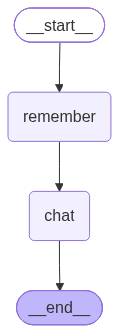

In [51]:
builder = StateGraph(MessagesState)
builder.add_node("remember", remember_node)
builder.add_node("chat", chat_node)

builder.add_edge(START, "remember")
builder.add_edge("remember", "chat")
builder.add_edge("chat", END)

graph = builder.compile(store=store)

graph

In [52]:
config = {"configurable": {"user_id": "u1"}}

In [55]:
result = graph.invoke({"messages": [{"role": "user", "content": "Hi, my name is Nitish"}]}, config)
result['messages'][-1].content

'Hi Nitish! 👋 Great to meet you. How can I help you today?  \n\n---\n\n**A few quick ideas to get us started:**\n\n1. **What are you working on right now?**  \n   Whether it’s a coding project, a hobby, or something you’re learning, I can dive in with tips, resources, or troubleshooting help.\n\n2. **Do you have any favorite tools or languages?**  \n   Knowing whether you’re into Python, JavaScript, cloud services, etc., lets me tailor examples and suggestions just for you.\n\n3. **Anything specific you’d like to explore or improve?**  \n   From productivity hacks to deep‑dive technical topics, I’m happy to dive in.\n\n---\n\n**Feel free to let me know what’s on your mind, and we’ll take it from there!**  \n\n---  \n\n**Suggested follow‑up questions:**  \n1. What project or task are you currently focused on?  \n2. Which programming languages or frameworks do you enjoy working with the most?  \n3. Is there a particular problem or topic you’d like help solving today?'

In [56]:
for it in store.search(("user", "u1", "details")):
    print(it.value["data"])

User's name is Nitish


In [57]:
result = graph.invoke({"messages": [{"role": "user", "content": "I teach AI on YouTube"}]}, config)
print(result['messages'][-1].content)

Sure thing, Nitish! 🎉  

Teaching AI on YouTube is a fantastic way to share knowledge and inspire the next generation of creators. If there’s anything specific you’d like help with—whether it’s brainstorming video topics, polishing scripts, optimizing thumbnails, setting up a production workflow, or even diving into the technical details of the models you showcase—just let me know. I’m happy to tailor suggestions to fit your style and audience.  

**A few quick ideas you might find useful:**

| Area | Quick Tip |
|------|-----------|
| **Content Planning** | Create a “topic calendar” that aligns with major AI conferences (NeurIPS, CVPR, etc.) and trending research papers. This keeps your channel timely and gives viewers a reason to subscribe for regular updates. |
| **Script Writing** | Use a two‑pass approach: first draft a concise “hook” (first 30 seconds) that teases the main insight, then flesh out the technical explanation with analogies that match your audience’s background. |
| 

In [58]:
for it in store.search(("user", "u1", "details")):
    print(it.value["data"])

User's name is Nitish
User teaches AI on YouTube.


In [59]:
result = graph.invoke({"messages": [{"role": "user", "content": "Explain GenAI simply"}]}, config)
print(result['messages'][-1].content)

Sure, Nitish — let’s break down Generative AI in the simplest way possible.

---

## What is Generative AI?

**Generative AI** is a type of artificial intelligence that can **create new content**—like text, images, music, or code—rather than just analyzing or classifying what already exists.

| Traditional AI | Generative AI |
|----------------|---------------|
| **What it does:** Recognizes patterns (e.g., spam filter, image classifier) | **What it does:** Produces something new (e.g., writes a story, draws a picture) |
| **Input → Decision** | **Input → Creation** |
| Example: “Is this email spam?” → Yes/No | Example: “Write a short poem about sunrise.” → Poem |

---

## How Does It Work? (A Simple Analogy)

1. **Learning Phase (Reading a Library)**  
   The model reads *massive* amounts of data—think of it as devouring an entire library of books, thousands of photos, or millions of code snippets. It learns the statistical relationships between words, pixels, notes, etc.

2. **Genera

In [60]:
for it in store.search(("user", "u1", "details")):
    print(it.value["data"])

User's name is Nitish
User teaches AI on YouTube.
